In [1]:
from os.path import exists
import matplotlib.pyplot as plt
import pdb

import numpy as np
import time
from astropy.io import fits
from astropy.stats import sigma_clipped_stats as sigclip
from scipy.interpolate import UnivariateSpline
from scipy.interpolate import splev
from scipy.interpolate import splrep
from scipy.optimize import curve_fit
import scipy.signal as sgl

from jwst.assign_wcs import nirspec
from jwst import datamodels
from photutils.detection import DAOStarFinder
from jwst.extract_1d.ifu import get_coordinates as cubecoord

In [2]:
# Main function
everyn=3
nmed=9
nslices=30
slices=np.arange(nslices)
verbose=True

# Fluxcal program
#file='/Users/dlaw/FlightData/APT1536_OtherInst/NRSifu/b11.0/jw01536003001_10101_00001_nrs1_cal.fits'
#targra=hdu[0].header['TARG_RA']
#targdec=hdu[0].header['TARG_DEC']
#maskrad=1000# Arcseconds beyond which to mask

# Tracy program: PRISM
file='/Users/dlaw/FlightData/APT6641_tracy/data/Obs01/stage2/jw06641001001_03101_00001_nrs1_cal.fits'
# Cube file for comparison
file3d='/Users/dlaw/FlightData/APT6641_tracy/data/Obs01/stage2/jw06641001001_03101_00001_nrs1_prism-clear_s3d.fits'
targra=155.9964811
targdec=-57.7583002
#targra=155.9972715
#targdec=-57.7584841
maskrad=0.7# Arcseconds beyond which to mask


# Tracy program: G140H/F070LP
file='/Users/dlaw/FlightData/APT6641_tracy/data/Obs02/stage2/jw06641002001_02101_00001_nrs1_cal.fits'
# Cube file for comparison
file3d='/Users/dlaw/FlightData/APT6641_tracy/data/Obs02/stage2/jw06641002001_02101_00001_nrs1_g140h-f070lp_s3d.fits'
targra=156.0104745
targdec=-57.7584544
maskrad=0.7# Arcseconds beyond which to mask

hdu=fits.open(file)
data=hdu['SCI'].data

# What grating/filter?
hdu[0].header
filt=hdu[0].header['FILTER']
grating=hdu[0].header['GRATING']

In [3]:
def gauss1d(x, A, mu, sigma, baseline):
    return  A*np.exp(-(x-mu)**2/(2*sigma)**2) + baseline

In [4]:
def xy_to_abl(inx,iny,file, snum=None):
    nslice=30
    im=datamodels.ImageModel(file)
    
    x=inx.ravel()
    y=iny.ravel()
    
    # Big structure to save all the returned values
    aall=np.zeros([len(x),nslice])
    ball=np.zeros([len(x),nslice])
    lamall=np.zeros([len(x),nslice])
    slall=np.zeros([len(x),nslice])
    
    # If passed in snum, that contains the known slice numbers of input x/y
    # Only need to loop over those
    # Awkward in practice since we're using snum_ord instead....
    if snum != None:
        loopslice=np.unique(snum[np.isfinite(snum)])
    else:
        loopslice=np.arange(nslice)
    
    for ii in range(0,len(loopslice)):
        xform=(nirspec.nrs_wcs_set_input(im,loopslice[ii])).get_transform('detector','slicer')
        ball[:,ii],aall[:,ii],lamall[:,ii]=xform(x,y)
        slall[:,ii]=ii

    # slice all is nan where aall is nan
    a_1d=aall.reshape(-1)
    sl_1d=slall.reshape(-1)
    finite=(np.isfinite(a_1d))
    indx=(np.where(finite == False))[0]
    if (len(indx) > 0):
        sl_1d[indx]=np.nan

    a=np.nanmedian(aall,axis=1).reshape(inx.shape)
    b=np.nanmedian(ball,axis=1).reshape(inx.shape)
    lam=np.nanmedian(lamall,axis=1).reshape(inx.shape)
    sl=np.nanmedian(slall,axis=1).reshape(inx.shape)
    
    return a,b,lam,sl

In [5]:
def abl_to_v2v3(alpha,beta,lam,file):
    im=datamodels.ImageModel(file)
    # We can pick any slice, doesn't matter
    xform=(nirspec.nrs_wcs_set_input(im,0)).get_transform('slicer','v2v3')
    v2,v3,_=xform(beta,alpha,lam)
    
    return v2,v3

In [6]:
def abl_to_radec(alpha,beta,lam,file):
    im=datamodels.ImageModel(file)
    # We can pick any slice, doesn't matter
    xform=(nirspec.nrs_wcs_set_input(im,0)).get_transform('slicer','world')
    ra,dec,_=xform(beta,alpha,lam)
    
    return ra,dec

In [7]:
# Trace in a single slice in x/y units
def trace_slice(thisslice,data,snum,basex,basey,nmed,everyn,verbose=False):
    ysize,xsize=data.shape
    
    # Zero out everything outside this slice
    indx=np.where(snum == thisslice)
    data_slice=np.zeros_like(data)
    data_slice[indx]=data[indx]
    data_slice[np.isfinite(data_slice) == False] = 0
    ymin,ymax=np.min(basey[indx]),np.max(basey[indx])
    
    # Where were the ends of the slice in wavelength?
    temp=np.nansum(data_slice,axis=0)
    indx=np.where(temp != 0)
    valid_xmin,valid_xmax = np.nanmin(indx),np.nanmax(indx)
    
    if verbose:
        temp=fits.PrimaryHDU(data_slice)
        temp.writeto('slice.fits',overwrite=True)
    
    if verbose:
        print('First pass trace fitting')
    ycen_pass1=np.zeros(xsize)
    for ii in range(valid_xmin,valid_xmax):
        xstart = max(0,int(ii-nmed/2))
        xstop = min(xsize,xstart+nmed)
        cut=np.nanmedian(data_slice[:,xstart:xstop],axis=1)
        ycen_pass1[ii]=np.argmax(cut)
    # NaN-out any results with ycen_pass=0 (those are where no data off ends of spectrum)
    indx=np.where(ycen_pass1 == 0)
    ycen_pass1[indx]=np.nan
    # Clean up any bad values by looking for 3sigma outliers
    # and replacing them with the median value
    med,_,rms=sigclip(ycen_pass1)
    indx=np.where((ycen_pass1 < med-3*rms) | (ycen_pass1 > med+3*rms))
    #ycen_pass1[indx]=med
    ywid_pass1=np.ones(xsize) # First pass width is 1 pixel
    
    # Second pass for y locations along the trace within this slice
    if verbose:
        print('Second pass trace fitting')
    ycen_pass2=np.empty(xsize)
    ycen_pass2[:]=np.nan
    ywid_pass2=np.empty(xsize)
    ywid_pass2[:]=np.nan
    for ii in range(valid_xmin,valid_xmax,everyn):
        ytemp=np.arange(ymin,ymax,1)
        ftemp=data_slice[ytemp,ii]
        
        # Initial guess at fit parameters
        p0=[ftemp.max(),ycen_pass1[ii],ywid_pass1[ii],0.]
        # Bounds for fit parameters
        bound_low=[0.,ycen_pass1[ii]-3*rms,0,-ftemp.max()]
        bound_hi=[10*np.max(ftemp),ycen_pass1[ii]+3*rms,10,ftemp.max()]
        # Do the fit
        try:
            popt,_ = curve_fit(gauss1d, ytemp, ftemp, p0=p0, bounds=(bound_low,bound_hi), method='trf')
        except:
            popt=p0
        ycen_pass2[ii]=popt[1]
        ywid_pass2[ii]=popt[2]
        
    # Third pass for y location; use a fixed profile width
    twidth=np.nanmedian(ywid_pass2)
    yamp_pass3=np.empty(xsize)
    yamp_pass3[:]=np.nan
    ybase_pass3=np.empty(xsize)
    ybase_pass3[:]=np.nan
    ycen_pass3=np.empty(xsize)
    ycen_pass3[:]=np.nan
    if verbose:
        print('Third pass trace fitting, median trace width ',twidth, ' pixels')
    for ii in range(valid_xmin,valid_xmax,everyn):
        ytemp=np.arange(ymin,ymax,1)
        ftemp=data_slice[ytemp,ii]
        
        # Initial guess at fit parameters
        p0=[ftemp.max(),ycen_pass2[ii],twidth,0.]
        # Bounds for fit parameters
        bound_low=[0.,ycen_pass2[ii]-3*rms,twidth*0.999,-ftemp.max()]
        bound_hi=[10*np.max(ftemp),ycen_pass2[ii]+3*rms,twidth*1.001,ftemp.max()]
        # Do the fit
        try:
            popt,_ = curve_fit(gauss1d, ytemp, ftemp, p0=p0, bounds=(bound_low,bound_hi), method='trf')
        except:
            popt=p0
        yamp_pass3[ii]=popt[0]
        ycen_pass3[ii]=popt[1]
        ybase_pass3[ii]=popt[3]
        
    # Clean up the fit to remove outliers
    thisbasex=basex[0,:]
    qual=np.ones(xsize)
    # Low order polynomial fit to replace nans
    good=np.where(np.isfinite(ycen_pass3) == True)
    fit=np.polyfit(thisbasex[good],ycen_pass3[good],3)
    model=np.polyval(fit,thisbasex)
    indx=np.where(np.isfinite(ycen_pass3) == False)
    qual[indx]=0
    #ycen_pass3[indx]=model[indx]
    # Standard deviation clipping to replace outliers
    indx=np.where(np.abs(ycen_pass3-model) > 3*np.nanstd(ycen_pass3[good]-model[good]))
    qual[indx]=0
    good=(np.where(qual == 1))[0]
    # Another fit to find lesser outliers using sigma-clipped RMS
    fit=np.polyfit(thisbasex[good],ycen_pass3[good],2)
    model=np.polyval(fit,thisbasex)
    indx=np.where(np.abs(ycen_pass3-model) > 3*(sigclip(ycen_pass3[good]-model[good])[2]))
    qual[indx]=0
    # NaN out things beyond the wavelength ends
    indx=np.where((thisbasex < valid_xmin)|(thisbasex > valid_xmax))
    ycen_pass3[indx]=np.nan
    # Find any nan values and set them to bad quality
    indx=np.where(np.isfinite(ycen_pass3) != True)
    qual[indx]=0
    # Final model fit
    bad=(np.where(qual == 0))[0]
    ycen_pass3[bad]=np.nan
    good=(np.where(qual == 1))[0]
    fit=np.polyfit(thisbasex[good],ycen_pass3[good],3)
    model=np.polyval(fit,thisbasex)
    # NaN out things beyond the wavelength ends
    indx=np.where((thisbasex < valid_xmin)|(thisbasex > valid_xmax))
    model[indx]=np.nan
    
    return ycen_pass2,ycen_pass3,model

In [8]:
# Compute alpha/beta/lam for every pixel
basex,basey = np.meshgrid(np.arange(2048),np.arange(2048))
nx,ny=2048,2048

# Pre-compute a slice map that we'll use to make later computations faster
alpha,beta,lam,snum=xy_to_abl(basex,basey,file)

# Temporary computation of ra/dec for each pixel
ratemp,dectemp=abl_to_radec(alpha,beta,lam,file)
# Distance from nominal point in arcsec
dratemp=(ratemp-targra)*np.cos(targdec*3.14159/180.)*3600
ddectemp=(dectemp-targdec)*3600
dist=np.sqrt(dratemp*dratemp + ddectemp*ddectemp)
# Mask where distance is larger than mask radius
indx=np.where(dist > maskrad)
data[indx]=0

# Rough computation of alpha pixel size
dratemp=np.diff(ratemp,axis=0)*np.cos(targdec*3.14159/180.)*3600
ddectemp=np.diff(dectemp,axis=0)*3600
pixsize_alpha=np.sqrt(dratemp*dratemp + ddectemp*ddectemp)
ps_alpha=np.nanmedian(pixsize_alpha)
#junk=fits.PrimaryHDU(pixsize_alpha)
#junk.writeto('psize.fits',overwrite=True)

temp=fits.PrimaryHDU(alpha)
temp.writeto('aa.fits',overwrite=True)
temp=fits.PrimaryHDU(beta)
temp.writeto('bb.fits',overwrite=True)
temp=fits.PrimaryHDU(ratemp)
temp.writeto('ra.fits',overwrite=True)
temp=fits.PrimaryHDU(dectemp)
temp.writeto('dec.fits',overwrite=True)
temp=fits.PrimaryHDU(dist)
temp.writeto('dist.fits',overwrite=True)
temp=fits.PrimaryHDU(data)
temp.writeto('data.fits',overwrite=True)

2024-11-05 14:28:40,949 - stpipe - WARNING - /var/folders/lg/jw_brb093bl9n39fbgn1cw080001fw/T/ipykernel_75112/4236242922.py:35: RuntimeWarning: All-NaN slice encountered
  a=np.nanmedian(aall,axis=1).reshape(inx.shape)

2024-11-05 14:28:44,324 - stpipe - WARNING - /var/folders/lg/jw_brb093bl9n39fbgn1cw080001fw/T/ipykernel_75112/4236242922.py:36: RuntimeWarning: All-NaN slice encountered
  b=np.nanmedian(ball,axis=1).reshape(inx.shape)

2024-11-05 14:28:47,766 - stpipe - WARNING - /var/folders/lg/jw_brb093bl9n39fbgn1cw080001fw/T/ipykernel_75112/4236242922.py:37: RuntimeWarning: All-NaN slice encountered
  lam=np.nanmedian(lamall,axis=1).reshape(inx.shape)

2024-11-05 14:28:51,279 - stpipe - WARNING - /var/folders/lg/jw_brb093bl9n39fbgn1cw080001fw/T/ipykernel_75112/4236242922.py:38: RuntimeWarning: All-NaN slice encountered
  sl=np.nanmedian(slall,axis=1).reshape(inx.shape)



2024-11-05 14:28:57,326 - stpipe - WARNING - /Users/dlaw/anaconda3/envs/jwst/lib/python3.11/site-packages/numpy/lib/nanfunctions.py:1217: RuntimeWarning: All-NaN slice encountered
  return function_base._ureduce(a, func=_nanmedian, keepdims=keepdims,



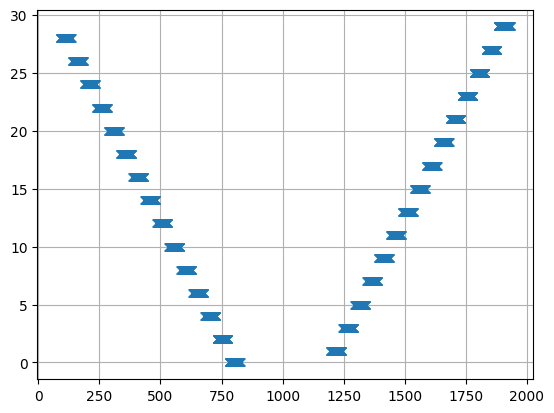

In [9]:
# NIRSpec slice numbers are awkward- not next to each other on sky or det

# Define snum_ord which will be the bottom-top ordered snum
temp=np.nanmedian(snum,axis=1)
indexes = np.unique(temp, return_index=True)[1]
ordering=[temp[index] for index in sorted(indexes)][1:]

snum_ord=snum.copy()
for ii in range(0,nslices):
    indx=np.where(snum == ordering[ii])
    snum_ord[indx]=ii

plt.plot(temp,'x')
plt.grid()

temp=fits.PrimaryHDU(snum)
temp.writeto('snum.fits',overwrite=True)
temp=fits.PrimaryHDU(snum_ord)
temp.writeto('snum_ord.fits',overwrite=True)

2024-11-05 14:29:00,741 - stpipe - WARNING - /var/folders/lg/jw_brb093bl9n39fbgn1cw080001fw/T/ipykernel_75112/895323475.py:7: RuntimeWarning: All-NaN slice encountered
  cut=np.nanmedian(data[:,xstart:xstop],axis=1)



11


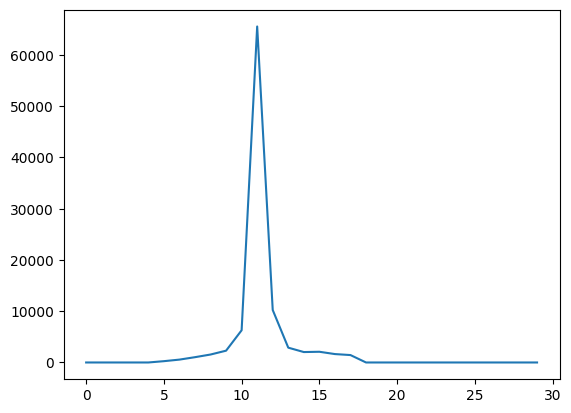

In [10]:
# Identify the peak slice
if (hdu[0].header['GRATING'] == 'PRISM'):
    xstart=663
else:
    xstart=int(nx/2 - nmed/2)
xstop=xstart+nmed
cut=np.nanmedian(data[:,xstart:xstop],axis=1)
slicecut=snum_ord[:,int(nx/2)]
slicesum=np.zeros(nslices)
# in different slices
for ii in range(0,nslices):
    indx=np.where(slicecut == slices[ii])
    slicesum[ii]=np.nansum(cut[indx])
# Which slice is the peak in?
peakslice=slices[np.argmax(slicesum)]

plt.plot(slicesum)
print(peakslice)

In [11]:
# Define central beta of the ordered slices
slice_beta=np.zeros(nslices)
for ii in range(0,nslices):
    # Use any pixel in the slice to get the beta
    indx=np.where(snum_ord == slices[ii])
    slice_beta[ii]=np.nanmedian(beta[indx])
# Define absolute beta ranges (top of top slice to bottom of bottom slice)
dbeta=np.abs(slice_beta[0]-slice_beta[1])
minbeta=np.min(slice_beta)-dbeta/2.
maxbeta=np.max(slice_beta)+dbeta/2.

# Define slice boundaries in beta
slice_beta_boundaries=np.arange(minbeta,maxbeta,dbeta)

Text(0, 0.5, 'Beta (meters)')

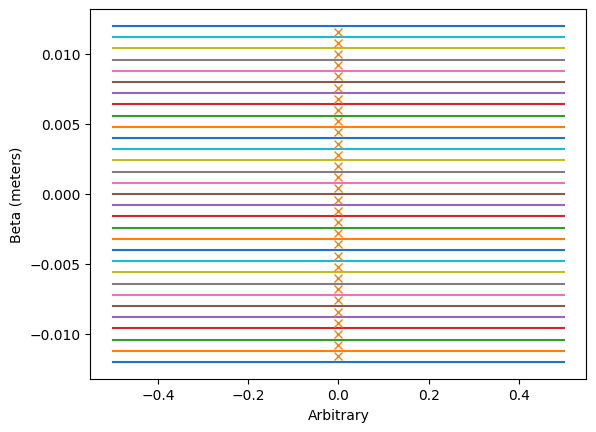

In [12]:
for ii in range(0,len(slice_beta_boundaries)):
    plt.plot([-0.5,0.5],[slice_beta_boundaries[ii],slice_beta_boundaries[ii]])
plt.plot(np.zeros_like(slice_beta),slice_beta,'x')
plt.xlabel('Arbitrary')
plt.ylabel('Beta (meters)')

First pass trace fitting


2024-11-05 14:29:10,911 - stpipe - WARNING - /Users/dlaw/anaconda3/envs/jwst/lib/python3.11/site-packages/astropy/stats/sigma_clipping.py:446: AstropyUserWarning: Input data contains invalid values (NaNs or infs), which were automatically clipped.
  warnings.warn(



Second pass trace fitting
Third pass trace fitting, median trace width  0.4076449388449366  pixels


2024-11-05 14:29:45,136 - stpipe - WARNING - /var/folders/lg/jw_brb093bl9n39fbgn1cw080001fw/T/ipykernel_75112/4236242922.py:35: RuntimeWarning: All-NaN slice encountered
  a=np.nanmedian(aall,axis=1).reshape(inx.shape)

2024-11-05 14:29:45,141 - stpipe - WARNING - /var/folders/lg/jw_brb093bl9n39fbgn1cw080001fw/T/ipykernel_75112/4236242922.py:36: RuntimeWarning: All-NaN slice encountered
  b=np.nanmedian(ball,axis=1).reshape(inx.shape)

2024-11-05 14:29:45,147 - stpipe - WARNING - /var/folders/lg/jw_brb093bl9n39fbgn1cw080001fw/T/ipykernel_75112/4236242922.py:37: RuntimeWarning: All-NaN slice encountered
  lam=np.nanmedian(lamall,axis=1).reshape(inx.shape)

2024-11-05 14:29:45,164 - stpipe - WARNING - /var/folders/lg/jw_brb093bl9n39fbgn1cw080001fw/T/ipykernel_75112/4236242922.py:38: RuntimeWarning: All-NaN slice encountered
  sl=np.nanmedian(slall,axis=1).reshape(inx.shape)



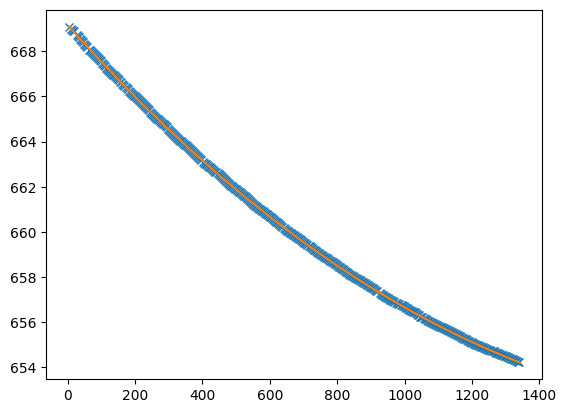

In [13]:
# Trace of the peak slice
ytrace_mid_pass2,ytrace_mid_pass3,ytrace_mid_poly=trace_slice(peakslice,data,snum_ord,basex,basey,nmed, everyn,verbose)
alpha_mid,beta_mid,lam_mid,_=xy_to_abl(np.arange(nx),ytrace_mid_poly,file)

plt.plot(ytrace_mid_pass3,'x')
plt.plot(ytrace_mid_poly)

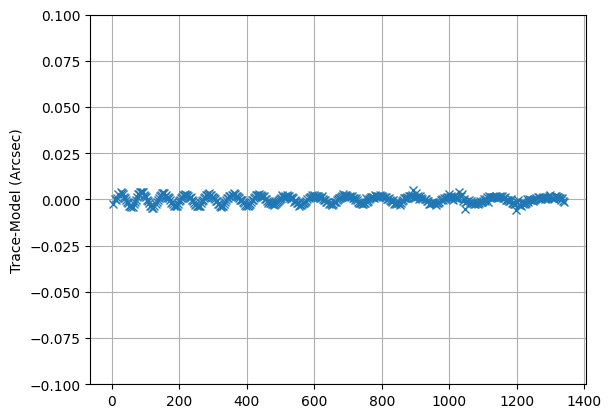

In [14]:
plt.plot(ps_alpha*(ytrace_mid_pass3-ytrace_mid_poly),'x')
plt.ylabel('Trace-Model (Arcsec)')
plt.ylim(-0.1,0.1)
plt.grid()

In [15]:
# If slice-1 is defined (not outside IFU) measure trace in that slice too
if (peakslice-1) in snum:
    ytrace_lo_pass2,ytrace_lo_pass3,ytrace_lo_poly=trace_slice(peakslice-1,data,snum_ord,basex,basey,nmed, everyn,verbose)
else:
    ytrace_lo_pass2=ytrace_mid_pass2*0
    ytrace_lo_pass3=ytrace_mid_pass3*0
    ytrace_lo_poly=ytrace_mid_poly*0
alpha_lo,beta_lo,lam_lo,_=xy_to_abl(np.arange(nx),ytrace_lo_poly,file)

First pass trace fitting


2024-11-05 14:29:54,522 - stpipe - WARNING - /Users/dlaw/anaconda3/envs/jwst/lib/python3.11/site-packages/astropy/stats/sigma_clipping.py:446: AstropyUserWarning: Input data contains invalid values (NaNs or infs), which were automatically clipped.
  warnings.warn(



Second pass trace fitting
Third pass trace fitting, median trace width  0.573505194152039  pixels


2024-11-05 14:30:29,478 - stpipe - WARNING - /var/folders/lg/jw_brb093bl9n39fbgn1cw080001fw/T/ipykernel_75112/4236242922.py:35: RuntimeWarning: All-NaN slice encountered
  a=np.nanmedian(aall,axis=1).reshape(inx.shape)

2024-11-05 14:30:29,485 - stpipe - WARNING - /var/folders/lg/jw_brb093bl9n39fbgn1cw080001fw/T/ipykernel_75112/4236242922.py:36: RuntimeWarning: All-NaN slice encountered
  b=np.nanmedian(ball,axis=1).reshape(inx.shape)

2024-11-05 14:30:29,493 - stpipe - WARNING - /var/folders/lg/jw_brb093bl9n39fbgn1cw080001fw/T/ipykernel_75112/4236242922.py:37: RuntimeWarning: All-NaN slice encountered
  lam=np.nanmedian(lamall,axis=1).reshape(inx.shape)

2024-11-05 14:30:29,505 - stpipe - WARNING - /var/folders/lg/jw_brb093bl9n39fbgn1cw080001fw/T/ipykernel_75112/4236242922.py:38: RuntimeWarning: All-NaN slice encountered
  sl=np.nanmedian(slall,axis=1).reshape(inx.shape)



In [16]:
# If slice+1 is defined (not outside IFU) measure trace in that slice too
if (peakslice+1) in snum:
    ytrace_hi_pass2,ytrace_hi_pass3,ytrace_hi_poly=trace_slice(peakslice+1,data,snum_ord,basex,basey,nmed, everyn,verbose)
else:
    ytrace_hi_pass2=ytrace_mid_pass2*0
    ytrace_hi_pass3=ytrace_mid_pass3*0
    ytrace_hi_poly=ytrace_mid_poly*0
alpha_hi,beta_hi,lam_hi,_=xy_to_abl(np.arange(nx),ytrace_hi_poly,file)

First pass trace fitting


2024-11-05 14:30:30,237 - stpipe - WARNING - /Users/dlaw/anaconda3/envs/jwst/lib/python3.11/site-packages/astropy/stats/sigma_clipping.py:446: AstropyUserWarning: Input data contains invalid values (NaNs or infs), which were automatically clipped.
  warnings.warn(



Second pass trace fitting
Third pass trace fitting, median trace width  0.574867418519594  pixels


2024-11-05 14:31:05,390 - stpipe - WARNING - /var/folders/lg/jw_brb093bl9n39fbgn1cw080001fw/T/ipykernel_75112/4236242922.py:35: RuntimeWarning: All-NaN slice encountered
  a=np.nanmedian(aall,axis=1).reshape(inx.shape)

2024-11-05 14:31:05,396 - stpipe - WARNING - /var/folders/lg/jw_brb093bl9n39fbgn1cw080001fw/T/ipykernel_75112/4236242922.py:36: RuntimeWarning: All-NaN slice encountered
  b=np.nanmedian(ball,axis=1).reshape(inx.shape)

2024-11-05 14:31:05,401 - stpipe - WARNING - /var/folders/lg/jw_brb093bl9n39fbgn1cw080001fw/T/ipykernel_75112/4236242922.py:37: RuntimeWarning: All-NaN slice encountered
  lam=np.nanmedian(lamall,axis=1).reshape(inx.shape)

2024-11-05 14:31:05,411 - stpipe - WARNING - /var/folders/lg/jw_brb093bl9n39fbgn1cw080001fw/T/ipykernel_75112/4236242922.py:38: RuntimeWarning: All-NaN slice encountered
  sl=np.nanmedian(slall,axis=1).reshape(inx.shape)



In [32]:
# Fit the PSF centroid in the beta direction
ftemp=np.zeros(nslices)
xtemp=np.arange(nx)
bcen_vec=np.zeros(nx)*np.nan
bwid_vec=np.zeros(nx)*np.nan
dbeta=np.abs(np.nanmedian(np.diff(slice_beta)))

# Very crude spectrum along the center of the peak-slice trace
crudespec=data[np.round(ytrace_mid_poly).astype(int),xtemp]
# Very crude wavelengths for the center trace
crudewave=lam[np.round(ytrace_mid_poly).astype(int),xtemp]

# Where were the ends of the slice in wavelength?
indx=np.where(np.isfinite(ytrace_mid_poly))
valid_xmin,valid_xmax = np.nanmin(indx),np.nanmax(indx)

for ii in range(valid_xmin,valid_xmax,everyn):
    ftemp[:]=0.
    xstart=ii
    xstop=xstart+nmed
    if (xstop > nx):
        xstop=nx
        
    # What wavelengths is this x range atop the trace in the peak slice?
    lstart,lstop = np.nanmin(crudewave[xstart:xstop]), np.nanmax(crudewave[xstart:xstop])
    
    for jj in range(0,nslices):
        # What pixels does this lambda range correspond to for this slice?
        xindx=np.where((snum_ord == slices[jj])&(lam > lstart)&(lam < lstop))
        if (len(xindx[0]) > 0):
            #ftemp[jj]=np.nansum(data[xindx]) # Doesn't work as well
            thisxstart,thisxstop=np.nanmin(basex[xindx]),np.nanmax(basex[xindx])
            cut=np.nanmedian(data[:,thisxstart:thisxstop],axis=1)
            # We can't trivially fit the trace in each slice either, because it's too faint to
            # see in most, and the width changes from slice to slice.
            # Therefore just sum in a wavelength box.
            indx=np.where(snum_ord[:,ii] == slices[jj])
            ftemp[jj]=np.nansum(cut[indx])
        else:
            ftemp[jj]=np.nan
    # Initial guess at fit parameters
    p0=[ftemp.max(),slice_beta[np.argmax(ftemp)],dbeta/2.,0.]
    # Bounds for fit parameters.  Assume center MUST be somewhere in field.
    bound_low=[0.,minbeta,0,-ftemp.max()]
    bound_hi=[10*np.max(ftemp),maxbeta,dbeta*2,ftemp.max()]
    # Do the fit
    try:
        popt,_ = curve_fit(gauss1d, slice_beta, ftemp, p0=p0, bounds=(bound_low,bound_hi), method='trf')
    except:
        popt=p0
        
    # If any value in ftemp were NaN then not all slices had values at this wavelength,
    # and we'll fail out
    if (np.isfinite(np.sum(ftemp))):
        bcen_vec[ii]=popt[1]
        bwid_vec[ii]=popt[2]
    else:
        bcen_vec[ii]=np.nan
        bwid_vec[ii]=np.nan
# Due to slicers, there MUST only be one beta as a function of wavelength no matter
# the distortion solution
good=np.where(bcen_vec != 0) 
beta=np.nanmedian(bcen_vec[good])

# Final model fit
qual=np.zeros(nx)
good=np.where((xtemp > valid_xmin)&(xtemp < valid_xmax)&(np.isfinite(bcen_vec))&(np.isfinite(crudespec)))
qual[good]=1
fit=np.polyfit(xtemp[good],bcen_vec[good],3)
model=np.polyval(fit,xtemp)
# Reject outliers and refit
indx=np.where(np.abs(bcen_vec-model) > 3*np.nanstd(bcen_vec[good]-model[good]))
qual[indx]=0
good=(np.where(qual == 1))[0]
fit=np.polyfit(xtemp[good],bcen_vec[good],3)
beta_model=np.polyval(fit,xtemp)
bad=np.where((xtemp < valid_xmin)|(xtemp > valid_xmax))
beta_model[bad]=np.nan

2024-11-05 14:40:19,171 - stpipe - WARNING - /var/folders/lg/jw_brb093bl9n39fbgn1cw080001fw/T/ipykernel_75112/3760146794.py:9: RuntimeWarning: invalid value encountered in cast
  crudespec=data[np.round(ytrace_mid_poly).astype(int),xtemp]

2024-11-05 14:40:19,172 - stpipe - WARNING - /var/folders/lg/jw_brb093bl9n39fbgn1cw080001fw/T/ipykernel_75112/3760146794.py:11: RuntimeWarning: invalid value encountered in cast
  crudewave=lam[np.round(ytrace_mid_poly).astype(int),xtemp]

2024-11-05 14:40:19,294 - stpipe - WARNING - /Users/dlaw/anaconda3/envs/jwst/lib/python3.11/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)

2024-11-05 14:40:19,307 - stpipe - WARNING - /var/folders/lg/jw_brb093bl9n39fbgn1cw080001fw/T/ipykernel_75112/3760146794.py:35: RuntimeWarning: All-NaN slice encountered
  cut=np.nanmedian(data[:,thisxstart:thisxstop],axis=1)



4
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
7
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
10
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
13
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
16
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
19
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
22
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
25
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
28
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
31
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
34
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
37
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
40
0
1

6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
301
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
304
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
307
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
310
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
313
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
316
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
319
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
322
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
325
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
328
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
331
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
334
0
1


5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
595
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
598
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
601
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
604
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
607
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
610
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
613
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
616
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
619
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
622
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
625
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
628
0


4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
889
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
892
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
895
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
898
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
901
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
904
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
907
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
910
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
913
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
916
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
919
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
922


2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
1180
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
1183
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
1186
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
1189
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
1192
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
1195
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
1198
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
1201
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
1204
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
1207
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
1210
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
2

(2.232873397379875, 3.2589096289208612)

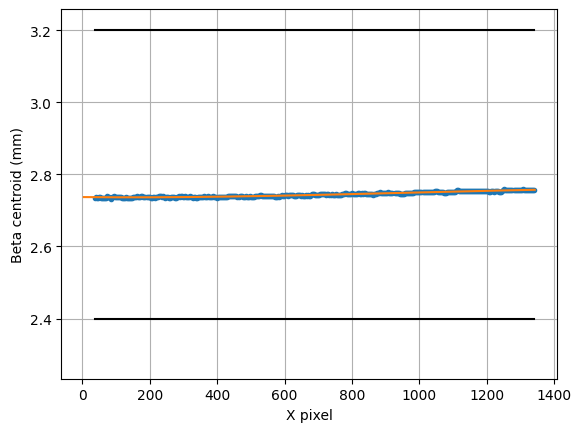

In [33]:
for ii in range(0,len(slice_beta_boundaries)):
    plt.plot([np.nanmin(xtemp[good]),np.nanmax(xtemp[good])],[1e3*slice_beta_boundaries[ii],1e3*slice_beta_boundaries[ii]],color='black')
plt.plot(xtemp[good],1e3*bcen_vec[good],'.')
plt.plot(xtemp,1e3*beta_model)
plt.grid()
plt.xlabel('X pixel')
plt.ylabel('Beta centroid (mm)')

plt.ylim(np.nanmin(1e3*bcen_vec[good])-0.5,np.nanmax(1e3*bcen_vec[good])+0.5)

# What does it mean that the beta centroid isn't constant with wavelength???
# Issue with fitting at fixed X?

In [19]:
# Convert alpha/beta to v2/v3 and ra/dec
#v2_mid,v3_mid = abl_to_v2v3(alpha_mid,beta_final,lam_mid,file)
#ra_mid,dec_mid = abl_to_radec(alpha_mid,beta_final,lam_mid,file)

v2_mid,v3_mid = abl_to_v2v3(alpha_mid,beta_model,lam_mid,file)
ra_mid,dec_mid = abl_to_radec(alpha_mid,beta_model,lam_mid,file)

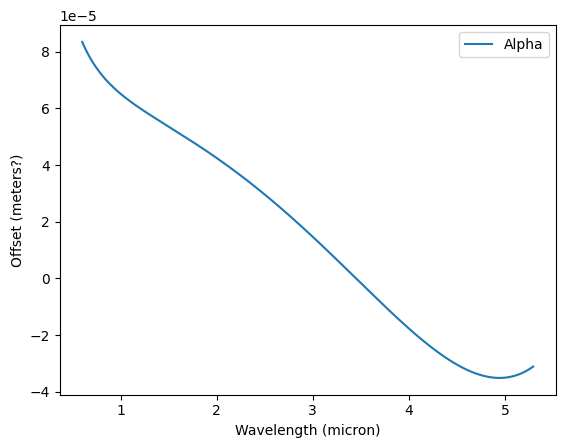

In [20]:
dalpha=alpha_mid-np.nanmedian(alpha_mid)

plt.plot(lam_mid*1e6,dalpha,label='Alpha')
plt.ylabel('Offset (meters?)')
plt.xlabel('Wavelength (micron)')
plt.legend()

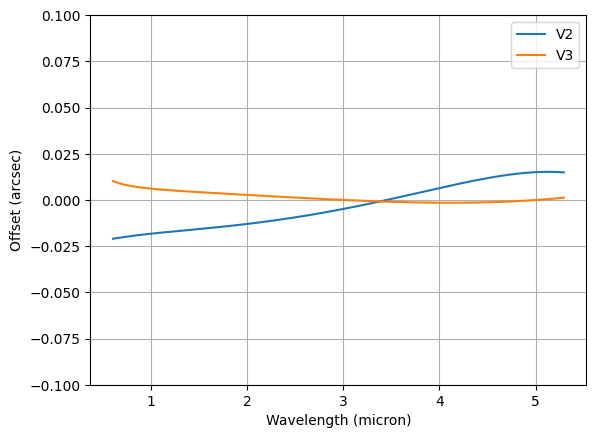

In [21]:
dv2=v2_mid-np.nanmedian(v2_mid)
dv3=v3_mid-np.nanmedian(v3_mid)

plt.plot(lam_mid*1e6,dv2,label='V2')
plt.plot(lam_mid*1e6,dv3,label='V3')
plt.ylabel('Offset (arcsec)')
plt.xlabel('Wavelength (micron)')
plt.legend()
plt.ylim(-0.1,0.1)
plt.grid()

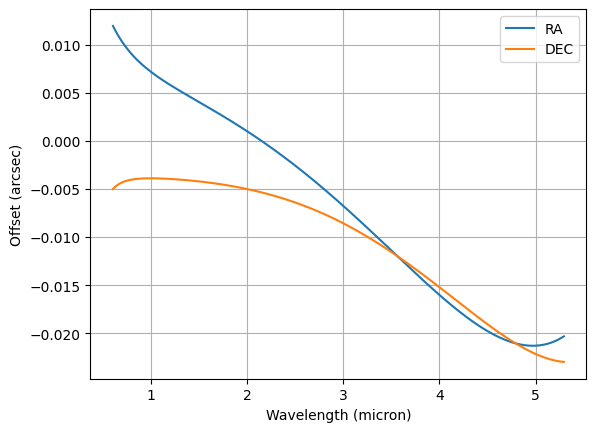

In [22]:
dra=(ra_mid-targra)*np.cos(np.nanmedian(dec_mid)*3.14159/180.)*3600
ddec=(dec_mid-targdec)*3600

plt.plot(lam_mid*1e6,dra,label='RA')
plt.plot(lam_mid*1e6,ddec,label='DEC')
plt.ylabel('Offset (arcsec)')
plt.xlabel('Wavelength (micron)')
plt.legend()
#plt.ylim(-0.1,0.1)
plt.grid()

Text(0, 0.5, 'DEC offset (arcsec)')

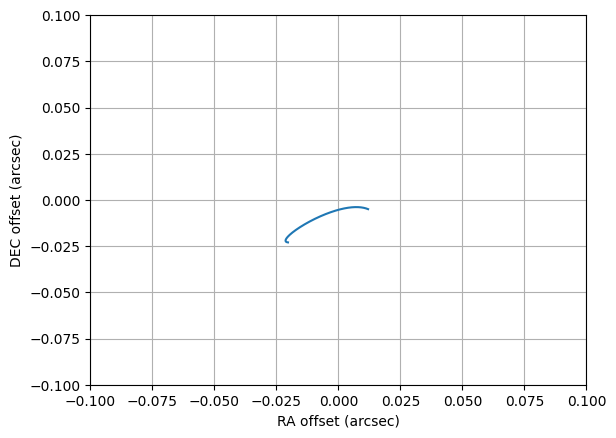

In [23]:
#rabox1,rabox2=targ_ra

plt.plot(dra,ddec)
plt.xlim(-0.1,0.1)
plt.ylim(-0.1,0.1)
plt.grid()
plt.xlabel('RA offset (arcsec)')
plt.ylabel('DEC offset (arcsec)')


In [24]:
# Compare to 3D cube fit
cube=datamodels.open(file3d)
cdata=cube.data
nz=cdata.shape[0]

In [25]:
cube_ra=np.zeros(nz)*np.nan
cube_dec=np.zeros(nz)*np.nan
cube_lam=np.zeros(nz)*np.nan

for ii in range(0,nz):
    _, clipmed, cliprms = sigclip(cdata[ii,:,:])
    clipmed,cliprms
    
    daofind = DAOStarFinder(fwhm=3.0, threshold=3 * cliprms)
    sources = daofind(cdata[ii,:,:] - clipmed)
    try:
        xfound=sources['xcentroid'].data
        yfound=sources['ycentroid'].data
        nfound=len(xfound)
        rafound,decfound=np.zeros(nfound),np.zeros(nfound)
        for jj in range(0,nfound):
            temp1,temp2,lcube=cubecoord(cube,xfound[jj],yfound[jj])
            rafound[jj]=temp1
            decfound[jj]=temp2
        if ii == 0:
            cube_lam=lcube
        
        dra_found=(rafound-targra)*np.cos(targdec*3.14159/180.)*3600
        ddec_found=(decfound-targdec)*3600
        dist_found=np.sqrt(dra_found*dra_found + ddec_found*ddec_found)
        cube_ra[ii]=rafound[np.argmin(dist_found)]
        cube_dec[ii]=decfound[np.argmin(dist_found)]
    except:
        pass
    
dra_cube=(cube_ra-targra)*np.cos(targdec*3.14159/180.)*3600
ddec_cube=(cube_dec-targdec)*3600

2024-10-29 17:53:48,989 - stpipe - WARNING - /Users/dlaw/anaconda3/envs/jwst/lib/python3.11/site-packages/astropy/stats/sigma_clipping.py:446: AstropyUserWarning: Input data contains invalid values (NaNs or infs), which were automatically clipped.
  warnings.warn(

2024-10-29 17:53:49,003 - stpipe - WARNING - /Users/dlaw/anaconda3/envs/jwst/lib/python3.11/site-packages/astropy/stats/sigma_clipping.py:446: AstropyUserWarning: Input data contains invalid values (NaNs or infs), which were automatically clipped.
  warnings.warn(

2024-10-29 17:53:49,007 - stpipe - WARNING - /Users/dlaw/anaconda3/envs/jwst/lib/python3.11/site-packages/astropy/stats/sigma_clipping.py:446: AstropyUserWarning: Input data contains invalid values (NaNs or infs), which were automatically clipped.
  warnings.warn(

2024-10-29 17:53:49,011 - stpipe - WARNING - /Users/dlaw/anaconda3/envs/jwst/lib/python3.11/site-packages/astropy/stats/sigma_clipping.py:446: AstropyUserWarning: Input data contains invalid values (NaN

2024-10-29 17:53:49,115 - stpipe - WARNING - /Users/dlaw/anaconda3/envs/jwst/lib/python3.11/site-packages/astropy/stats/sigma_clipping.py:446: AstropyUserWarning: Input data contains invalid values (NaNs or infs), which were automatically clipped.
  warnings.warn(

2024-10-29 17:53:49,118 - stpipe - WARNING - /Users/dlaw/anaconda3/envs/jwst/lib/python3.11/site-packages/astropy/stats/sigma_clipping.py:446: AstropyUserWarning: Input data contains invalid values (NaNs or infs), which were automatically clipped.
  warnings.warn(

2024-10-29 17:53:49,122 - stpipe - WARNING - /Users/dlaw/anaconda3/envs/jwst/lib/python3.11/site-packages/astropy/stats/sigma_clipping.py:446: AstropyUserWarning: Input data contains invalid values (NaNs or infs), which were automatically clipped.
  warnings.warn(

2024-10-29 17:53:49,126 - stpipe - WARNING - /Users/dlaw/anaconda3/envs/jwst/lib/python3.11/site-packages/astropy/stats/sigma_clipping.py:446: AstropyUserWarning: Input data contains invalid values (NaN

2024-10-29 17:53:49,236 - stpipe - WARNING - /Users/dlaw/anaconda3/envs/jwst/lib/python3.11/site-packages/astropy/stats/sigma_clipping.py:446: AstropyUserWarning: Input data contains invalid values (NaNs or infs), which were automatically clipped.
  warnings.warn(

2024-10-29 17:53:49,240 - stpipe - WARNING - /Users/dlaw/anaconda3/envs/jwst/lib/python3.11/site-packages/astropy/stats/sigma_clipping.py:446: AstropyUserWarning: Input data contains invalid values (NaNs or infs), which were automatically clipped.
  warnings.warn(

2024-10-29 17:53:49,244 - stpipe - WARNING - /Users/dlaw/anaconda3/envs/jwst/lib/python3.11/site-packages/astropy/stats/sigma_clipping.py:446: AstropyUserWarning: Input data contains invalid values (NaNs or infs), which were automatically clipped.
  warnings.warn(

2024-10-29 17:53:49,248 - stpipe - WARNING - /Users/dlaw/anaconda3/envs/jwst/lib/python3.11/site-packages/astropy/stats/sigma_clipping.py:446: AstropyUserWarning: Input data contains invalid values (NaN

2024-10-29 17:53:49,374 - stpipe - WARNING - /Users/dlaw/anaconda3/envs/jwst/lib/python3.11/site-packages/astropy/stats/sigma_clipping.py:446: AstropyUserWarning: Input data contains invalid values (NaNs or infs), which were automatically clipped.
  warnings.warn(

2024-10-29 17:53:49,379 - stpipe - WARNING - /Users/dlaw/anaconda3/envs/jwst/lib/python3.11/site-packages/astropy/stats/sigma_clipping.py:446: AstropyUserWarning: Input data contains invalid values (NaNs or infs), which were automatically clipped.
  warnings.warn(

2024-10-29 17:53:49,383 - stpipe - WARNING - /Users/dlaw/anaconda3/envs/jwst/lib/python3.11/site-packages/astropy/stats/sigma_clipping.py:446: AstropyUserWarning: Input data contains invalid values (NaNs or infs), which were automatically clipped.
  warnings.warn(

2024-10-29 17:53:49,388 - stpipe - WARNING - /Users/dlaw/anaconda3/envs/jwst/lib/python3.11/site-packages/astropy/stats/sigma_clipping.py:446: AstropyUserWarning: Input data contains invalid values (NaN

2024-10-29 17:53:49,519 - stpipe - WARNING - /Users/dlaw/anaconda3/envs/jwst/lib/python3.11/site-packages/astropy/stats/sigma_clipping.py:446: AstropyUserWarning: Input data contains invalid values (NaNs or infs), which were automatically clipped.
  warnings.warn(

2024-10-29 17:53:49,524 - stpipe - WARNING - /Users/dlaw/anaconda3/envs/jwst/lib/python3.11/site-packages/astropy/stats/sigma_clipping.py:446: AstropyUserWarning: Input data contains invalid values (NaNs or infs), which were automatically clipped.
  warnings.warn(

2024-10-29 17:53:49,529 - stpipe - WARNING - /Users/dlaw/anaconda3/envs/jwst/lib/python3.11/site-packages/astropy/stats/sigma_clipping.py:446: AstropyUserWarning: Input data contains invalid values (NaNs or infs), which were automatically clipped.
  warnings.warn(

2024-10-29 17:53:49,534 - stpipe - WARNING - /Users/dlaw/anaconda3/envs/jwst/lib/python3.11/site-packages/astropy/stats/sigma_clipping.py:446: AstropyUserWarning: Input data contains invalid values (NaN

2024-10-29 17:53:49,671 - stpipe - WARNING - /Users/dlaw/anaconda3/envs/jwst/lib/python3.11/site-packages/astropy/stats/sigma_clipping.py:446: AstropyUserWarning: Input data contains invalid values (NaNs or infs), which were automatically clipped.
  warnings.warn(

2024-10-29 17:53:49,676 - stpipe - WARNING - /Users/dlaw/anaconda3/envs/jwst/lib/python3.11/site-packages/astropy/stats/sigma_clipping.py:446: AstropyUserWarning: Input data contains invalid values (NaNs or infs), which were automatically clipped.
  warnings.warn(

2024-10-29 17:53:49,681 - stpipe - WARNING - /Users/dlaw/anaconda3/envs/jwst/lib/python3.11/site-packages/astropy/stats/sigma_clipping.py:446: AstropyUserWarning: Input data contains invalid values (NaNs or infs), which were automatically clipped.
  warnings.warn(

2024-10-29 17:53:49,686 - stpipe - WARNING - /Users/dlaw/anaconda3/envs/jwst/lib/python3.11/site-packages/astropy/stats/sigma_clipping.py:446: AstropyUserWarning: Input data contains invalid values (NaN

... (21 outputs left out)

2024-10-29 17:53:53,058 - stpipe - WARNING - /Users/dlaw/anaconda3/envs/jwst/lib/python3.11/site-packages/astropy/stats/sigma_clipping.py:446: AstropyUserWarning: Input data contains invalid values (NaNs or infs), which were automatically clipped.
  warnings.warn(

2024-10-29 17:53:53,063 - stpipe - WARNING - /Users/dlaw/anaconda3/envs/jwst/lib/python3.11/site-packages/astropy/stats/sigma_clipping.py:446: AstropyUserWarning: Input data contains invalid values (NaNs or infs), which were automatically clipped.
  warnings.warn(

2024-10-29 17:53:53,068 - stpipe - WARNING - /Users/dlaw/anaconda3/envs/jwst/lib/python3.11/site-packages/astropy/stats/sigma_clipping.py:446: AstropyUserWarning: Input data contains invalid values (NaNs or infs), which were automatically clipped.
  warnings.warn(

2024-10-29 17:53:53,073 - stpipe - WARNING - /Users/dlaw/anaconda3/envs/jwst/lib/python3.11/site-packages/astropy/stats/sigma_clipping.py:446: AstropyUserWarning: Input data contains invalid values (NaN

2024-10-29 17:53:53,214 - stpipe - WARNING - /Users/dlaw/anaconda3/envs/jwst/lib/python3.11/site-packages/astropy/stats/sigma_clipping.py:446: AstropyUserWarning: Input data contains invalid values (NaNs or infs), which were automatically clipped.
  warnings.warn(

2024-10-29 17:53:53,219 - stpipe - WARNING - /Users/dlaw/anaconda3/envs/jwst/lib/python3.11/site-packages/astropy/stats/sigma_clipping.py:446: AstropyUserWarning: Input data contains invalid values (NaNs or infs), which were automatically clipped.
  warnings.warn(

2024-10-29 17:53:53,223 - stpipe - WARNING - /Users/dlaw/anaconda3/envs/jwst/lib/python3.11/site-packages/astropy/stats/sigma_clipping.py:446: AstropyUserWarning: Input data contains invalid values (NaNs or infs), which were automatically clipped.
  warnings.warn(

2024-10-29 17:53:53,227 - stpipe - WARNING - /Users/dlaw/anaconda3/envs/jwst/lib/python3.11/site-packages/astropy/stats/sigma_clipping.py:446: AstropyUserWarning: Input data contains invalid values (NaN

2024-10-29 17:53:53,366 - stpipe - WARNING - /Users/dlaw/anaconda3/envs/jwst/lib/python3.11/site-packages/astropy/stats/sigma_clipping.py:446: AstropyUserWarning: Input data contains invalid values (NaNs or infs), which were automatically clipped.
  warnings.warn(

2024-10-29 17:53:53,371 - stpipe - WARNING - /Users/dlaw/anaconda3/envs/jwst/lib/python3.11/site-packages/astropy/stats/sigma_clipping.py:446: AstropyUserWarning: Input data contains invalid values (NaNs or infs), which were automatically clipped.
  warnings.warn(

2024-10-29 17:53:53,375 - stpipe - WARNING - /Users/dlaw/anaconda3/envs/jwst/lib/python3.11/site-packages/astropy/stats/sigma_clipping.py:446: AstropyUserWarning: Input data contains invalid values (NaNs or infs), which were automatically clipped.
  warnings.warn(

2024-10-29 17:53:53,380 - stpipe - WARNING - /Users/dlaw/anaconda3/envs/jwst/lib/python3.11/site-packages/astropy/stats/sigma_clipping.py:446: AstropyUserWarning: Input data contains invalid values (NaN

2024-10-29 17:53:53,521 - stpipe - WARNING - /Users/dlaw/anaconda3/envs/jwst/lib/python3.11/site-packages/astropy/stats/sigma_clipping.py:446: AstropyUserWarning: Input data contains invalid values (NaNs or infs), which were automatically clipped.
  warnings.warn(

2024-10-29 17:53:53,527 - stpipe - WARNING - /Users/dlaw/anaconda3/envs/jwst/lib/python3.11/site-packages/astropy/stats/sigma_clipping.py:446: AstropyUserWarning: Input data contains invalid values (NaNs or infs), which were automatically clipped.
  warnings.warn(

2024-10-29 17:53:53,532 - stpipe - WARNING - /Users/dlaw/anaconda3/envs/jwst/lib/python3.11/site-packages/astropy/stats/sigma_clipping.py:446: AstropyUserWarning: Input data contains invalid values (NaNs or infs), which were automatically clipped.
  warnings.warn(

2024-10-29 17:53:53,538 - stpipe - WARNING - /Users/dlaw/anaconda3/envs/jwst/lib/python3.11/site-packages/astropy/stats/sigma_clipping.py:446: AstropyUserWarning: Input data contains invalid values (NaN

(-0.1, 0.1)

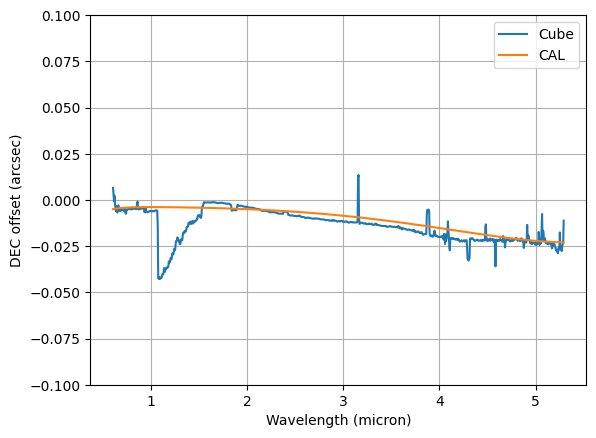

In [26]:
plt.plot(cube_lam,ddec_cube,label='Cube')
plt.plot(lam_mid*1e6,ddec,label='CAL')
plt.legend()
plt.xlabel('Wavelength (micron)')
plt.ylabel('DEC offset (arcsec)')
plt.grid()

plt.ylim(-0.1,0.1)

(-0.1, 0.1)

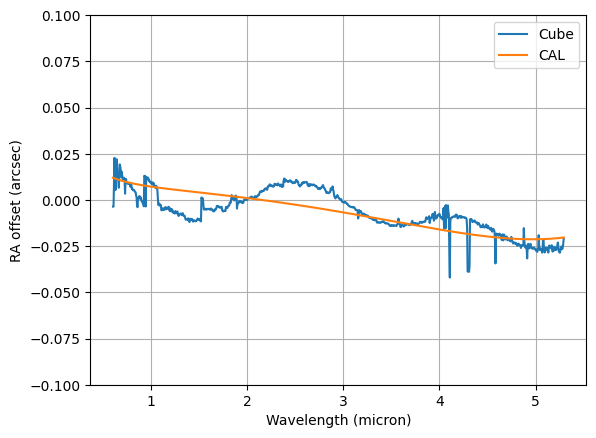

In [27]:
plt.plot(cube_lam,dra_cube,label='Cube')
plt.plot(lam_mid*1e6,dra,label='CAL')
plt.legend()
plt.xlabel('Wavelength (micron)')
plt.ylabel('RA offset (arcsec)')
plt.grid()
plt.ylim(-0.1,0.1)